# 02. Pipeline Single - Prova de Conceito (PoC) e Baseline
### Classificação de Patologias em Folhas de Macieira (*Plant Pathology 2020 - FGVC7*)

Este notebook implementa a **Etapa 2** da estratégia do projeto com configurações de alta performance e suporte nativo ao **Google Colab**:

1. **Suporte Nativo ao Google Colab:** Detecção automática de ambiente, montagem do Google Drive (`/content/drive`) e persistência segura em nuvem.
2. **Aceleração com Precisão Mista (`mixed_float16`):** Redução do uso de VRAM pela metade e aceleração computacional de até 3x na GPU Tesla T4, mantendo a camada de predição final em `float32`.
3. **Resolução Completa (512x512):** Imagens redimensionadas para alta resolução, preservando microdetalhes morfológicos das lesões.
4. **Pipeline Assíncrono com `tf.data` e Caching em Memória:** Imagens decodificadas mantidas em RAM (`.cache()`), garantindo 100% de utilização da GPU da 2ª época em diante.
5. **Backbone Descongelado (*Fine-Tuning*):** `DenseNet121` com base convolucional treinável e taxa de aprendizado controlada (`1e-4`).
6. **Ponderação por Classe (`class_weight`):** Balanceamento via pesos calculados pelo Scikit-Learn para priorizar o aprendizado da classe minoritária `multiple_diseases` (~5%).
7. **Monitoramento e Callbacks:** `EarlyStopping`, `ReduceLROnPlateau`, `CSVLogger` e `ModelCheckpoint` salvando o melhor modelo por `val_roc_auc`.

## 1. Importação de Bibliotecas, Suporte ao Google Colab e Configuração de Desempenho

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import layers, models, applications, callbacks, mixed_precision
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, auc
from sklearn.utils.class_weight import compute_class_weight

In [2]:

# 1.1 Suporte automático para execução no Google Colab
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    print("[*] Google Colab detectado! Montando Google Drive...")
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/ProjetosRedesNeurais'
    if os.path.exists(PROJECT_ROOT):
        os.chdir(PROJECT_ROOT)
        print(f"[*] Diretório de trabalho: {os.getcwd()}")
    else:
        print(f"[!] Aviso: {PROJECT_ROOT} não encontrado. Executando em: {os.getcwd()}")
else:
    print("[*] Ambiente Local detectado!")

[*] Google Colab detectado! Montando Google Drive...
Mounted at /content/drive
[*] Diretório de trabalho: /content/drive/MyDrive/ProjetosRedesNeurais


In [3]:
# 1.2 Configuração de Alta Performance: Precisão Mista (Mixed Precision)
# Reduz o consumo de VRAM em 50% e acelera o treino em GPUs Tesla T4 / RTX
try:
    mixed_precision.set_global_policy('mixed_float16')
    print(f"[*] Política de Precisão Mista ativada: {mixed_precision.global_policy().name}")
except Exception as e:
    print(f"[!] Aviso ao ativar mixed precision: {e}")

[*] Política de Precisão Mista ativada: mixed_float16


In [4]:
# 1.3 Detecção e configuração de aceleradores (GPU / TPU / CPU)
strategy = tf.distribute.get_strategy()
print(f"TensorFlow Version: {tf.__version__}")
print(f"Dispositivos físicos disponíveis: {tf.config.list_physical_devices()}")
print(f"Número de aceleradores em sincronia: {strategy.num_replicas_in_sync}")

TensorFlow Version: 2.21.0
Dispositivos físicos disponíveis: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Número de aceleradores em sincronia: 1


In [5]:
# 1.4 Diretórios do projeto
DATA_DIR = "data"
IMG_DIR = os.path.join(DATA_DIR, "images")
TRAIN_CSV = os.path.join(DATA_DIR, "train.csv")
TEST_CSV = os.path.join(DATA_DIR, "test.csv")
MODELS_DIR = "models"
GRAPHS_DIR = "graphs"

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(GRAPHS_DIR, exist_ok=True)

In [6]:
# 1.5 Hiperparâmetros de alta performance (Resolução 512x512)
IMG_HEIGHT, IMG_WIDTH = 512, 512
IMG_SHAPE = (IMG_HEIGHT, IMG_WIDTH, 3)
PER_REPLICA_BATCH = 16  # Seguro para resolução 512x512 na VRAM
BATCH_SIZE = PER_REPLICA_BATCH * strategy.num_replicas_in_sync
AUTOTUNE = tf.data.AUTOTUNE
EPOCHS_POC = 35
SEED = 42

print(f"Tamanho da imagem: {IMG_SHAPE} | Batch Size efetivo: {BATCH_SIZE} | Épocas teto: {EPOCHS_POC}")

Tamanho da imagem: (512, 512, 3) | Batch Size efetivo: 16 | Épocas teto: 35


## 2. Leitura dos Metadados, Divisão Estratificada e Class Weights

In [7]:
df = pd.read_csv(TRAIN_CSV)
TARGET_COLS = ["healthy", "multiple_diseases", "rust", "scab"]

# Caminho de cada imagem e mapeamento de classes
df["file_path"] = df["image_id"].apply(lambda x: os.path.join(IMG_DIR, f"{x}.jpg"))
df["label_str"] = df[TARGET_COLS].idxmax(axis=1)
df["label_idx"] = df[TARGET_COLS].values.argmax(axis=1)

# Divisão estratificada (80% treino / 20% validação)
train_df, val_df = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["label_idx"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

# Cálculo dos pesos balanceados por classe (Scikit-Learn)
classes = np.unique(train_df["label_idx"])
computed_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label_idx"].values
)
class_weight_dict = {int(c): float(w) for c, w in zip(classes, computed_weights)}

print(f"Total de amostras de treino: {len(train_df)}")
print(f"Total de amostras de validação: {len(val_df)}")
print("\nPesos por classe balanceados (class_weight):")


Total de amostras de treino: 1456
Total de amostras de validação: 365

Pesos por classe balanceados (class_weight):


In [8]:
for idx, col in enumerate(TARGET_COLS):
    qtd = (train_df["label_idx"] == idx).sum()
    print(f"  Classe {idx} ({col:<18}): {qtd:4d} amostras | Peso: {class_weight_dict[idx]:.4f}")

prop_comparison = pd.DataFrame({
    "Treino (N)": train_df["label_str"].value_counts(),
    "Treino (%)": (train_df["label_str"].value_counts() / len(train_df) * 100).round(2),
    "Validação (N)": val_df["label_str"].value_counts(),
    "Validação (%)": (val_df["label_str"].value_counts() / len(val_df) * 100).round(2)
})
display(prop_comparison)

  Classe 0 (healthy           ):  413 amostras | Peso: 0.8814
  Classe 1 (multiple_diseases ):   73 amostras | Peso: 4.9863
  Classe 2 (rust              ):  497 amostras | Peso: 0.7324
  Classe 3 (scab              ):  473 amostras | Peso: 0.7696


,Treino (N),Treino (%),Validação (N),Validação (%)
label_str,,,,
rust,497,34.13,125,34.25
scab,473,32.49,119,32.60
healthy,413,28.37,103,28.22
multiple_diseases,73,5.01,18,4.93


## 3. Pipeline com `tf.data.Dataset`, Caching em RAM e Data Augmentation

> **Otimização de Desempenho:** O pipeline decodifica as imagens para 512x512 e armazena em cache na RAM (`.cache()`). A partir da 2ª época, a leitura em disco é eliminada e os tensores são injetados diretamente na GPU, garantindo **100% de saturação do acelerador**.

In [9]:
# Camadas de Data Augmentation vetorizadas na GPU
data_augmentation_layers = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical", seed=SEED),
    layers.RandomRotation(0.15, seed=SEED),
    layers.RandomZoom(0.1, seed=SEED),
    layers.RandomTranslation(0.05, 0.05, seed=SEED)
], name="data_augmentation")

def process_image(file_path):
    """Carrega e decodifica a imagem diretamente para 512x512 em RGB."""
    img_bytes = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img_bytes, channels=3)
    img = tf.image.resize(img, [IMG_HEIGHT, IMG_WIDTH])
    return img

def create_dataset(dataframe, is_training=False):
    """Constrói o pipeline tf.data otimizado com cache na memória."""
    file_paths = dataframe["file_path"].values
    labels = dataframe[TARGET_COLS].values.astype(np.float32)

    ds = tf.data.Dataset.from_tensor_slices((file_paths, labels))
    ds = ds.map(lambda x, y: (process_image(x), y), num_parallel_calls=AUTOTUNE)

    # Caching em RAM: decodificação das imagens ocorre apenas na 1ª época
    ds = ds.cache()

    if is_training:
        ds = ds.shuffle(buffer_size=1024, seed=SEED)
        ds = ds.batch(BATCH_SIZE)
        ds = ds.map(lambda x, y: (data_augmentation_layers(x, training=True), y), num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.batch(BATCH_SIZE)

    ds = ds.prefetch(buffer_size=AUTOTUNE)
    return ds

train_ds = create_dataset(train_df, is_training=True)
val_ds = create_dataset(val_df, is_training=False)

print("Pipelines tf.data em 512x512 com Caching em RAM prontos!")

Pipelines tf.data em 512x512 com Caching em RAM prontos!


## 4. Construção do Modelo com Base Descongelada (*Fine-Tuning*) e Saída Float32

A `DenseNet121` é carregada com pesos do ImageNet, com **`trainable = True`**, taxa de aprendizado moderada (`1e-4`) e camada de saída em **`float32`** para máxima estabilidade numérica sob Mixed Precision.

In [10]:
def build_finetuned_densenet(input_shape=IMG_SHAPE, num_classes=4, dropout_rate=0.3, lr=1e-4):
    """Constrói o modelo com a base DenseNet121 descongelada para Fine-Tuning."""
    inputs = layers.Input(shape=input_shape, name="input_layer")

    # Pré-processamento oficial da DenseNet
    x = applications.densenet.preprocess_input(inputs)

    base_model = applications.DenseNet121(
        weights="imagenet",
        include_top=False,
        input_tensor=x
    )
    base_model.trainable = True  # Base convolucional descongelada

    x = layers.GlobalAveragePooling2D(name="gap")(base_model.output)
    x = layers.BatchNormalization(name="bn_top")(x)
    x = layers.Dropout(dropout_rate, name="dropout_head")(x)

    # Camada final com float32 explícito para estabilidade sob Mixed Precision
    outputs = layers.Dense(num_classes, activation="softmax", dtype="float32", name="predictions")(x)

    model = models.Model(inputs=inputs, outputs=outputs, name="FineTuned_DenseNet121")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="categorical_crossentropy",
        metrics=[
            "categorical_accuracy",
            tf.keras.metrics.AUC(name="roc_auc", multi_label=False)
        ]
    )
    return model

with strategy.scope():
    model = build_finetuned_densenet()

model.summary()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "FineTuned_DenseNet121"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 512, 512,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ true_divide         │ (None, 512, 512,  │          0 │ input_layer[0][0] │
│ (TrueDivide)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 512, 512,  │          0 │ true_divide[0][0] │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ true_divide_1       │ (None, 512, 512,  │          0 │ add[0][0]         │
│ (TrueDivide)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 518, 518,  │          0 │ true_divide_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 256, 256,  │      9,408 │ zero_padding2d[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 256, 256,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 256, 256,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_1    │ (None, 258, 258,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 128, 128,  │          0 │ zero_padding2d_1… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 128, 128,  │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 128, 128,  │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 128, 128,  │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 128, 128,  │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 128, 128,  │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 128, 128,  │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 128, 128,  │          0 │ pool1[0][0],    

 Total params: 7,045,700 (26.88 MB)

 Trainable params: 6,960,004 (26.55 MB)

 Non-trainable params: 85,696 (334.75 KB)

## 5. Treinamento Monitorado com Class Weights e Callbacks Avançados

- **`class_weight`:** Compensação balanceada ativa do desbalanceamento das classes.
- **`EarlyStopping`:** Monitoramento de `val_loss` (paciência = 8 épocas) com restauração dos melhores pesos.
- **`ReduceLROnPlateau`:** Decaimento dinâmico de taxa (`factor=0.2`, `patience=3`) para ajustar os gradientes.
- **`ModelCheckpoint`:** Salvamento automático dos pesos ótimos em `models/baseline_densenet121_best.keras`.
- **`CSVLogger`:** Persistência do histórico época a época no Google Drive para proteção contra desconexões do Colab.

In [11]:
CHECKPOINT_PATH = os.path.join(MODELS_DIR, "baseline_densenet121_best.keras")
LOG_CSV_PATH = os.path.join(MODELS_DIR, "baseline_densenet121_history.csv")

poc_callbacks = [
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),
    callbacks.ModelCheckpoint(
        filepath=CHECKPOINT_PATH,
        monitor="val_roc_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    callbacks.CSVLogger(LOG_CSV_PATH)
]

print(f"[*] Iniciando treinamento com Fine-Tuning em 512x512 por até {EPOCHS_POC} épocas...")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_POC,
    callbacks=poc_callbacks,
    class_weight=class_weight_dict
)

print(f"[*] Treinamento concluído com sucesso! Checkpoint salvo em: {CHECKPOINT_PATH}")

[*] Iniciando treinamento com Fine-Tuning em 512x512 por até 35 épocas...
Epoch 1/35
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - categorical_accuracy: 0.5214 - loss: 1.2281 - roc_auc: 0.7800
Epoch 1: val_roc_auc improved from None to 0.91655, saving model to models/baseline_densenet121_best.keras

Epoch 1: finished saving model to models/baseline_densenet121_best.keras
91/91 ━━━━━━━━━━━━━━━━━━━━ 1177s 4s/step - categorical_accuracy: 0.6641 - loss: 0.9177 - roc_auc: 0.8921 - val_categorical_accuracy: 0.6904 - val_loss: 0.7213 - val_roc_auc: 0.9166 - learning_rate: 1.0000e-04
Epoch 2/35
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - categorical_accuracy: 0.8522 - loss: 0.4842 - roc_auc: 0.9686
Epoch 2: val_roc_auc improved from 0.91655 to 0.97687, saving model to models/baseline_densenet121_best.keras

Epoch 2: finished saving model to models/baseline_densenet121_best.keras
91/91 ━━━━━━━━━━━━━━━━━━━━ 143s 2s/step - categorical_accuracy: 0.8393 - loss: 0.4967 - roc_auc: 0.9672 - val_categorical_accu

## 6. Curvas de Aprendizado e Métricas de Treinamento (300 DPI)

[*] Curvas salvas em: graphs/pipeline_single_curves.png


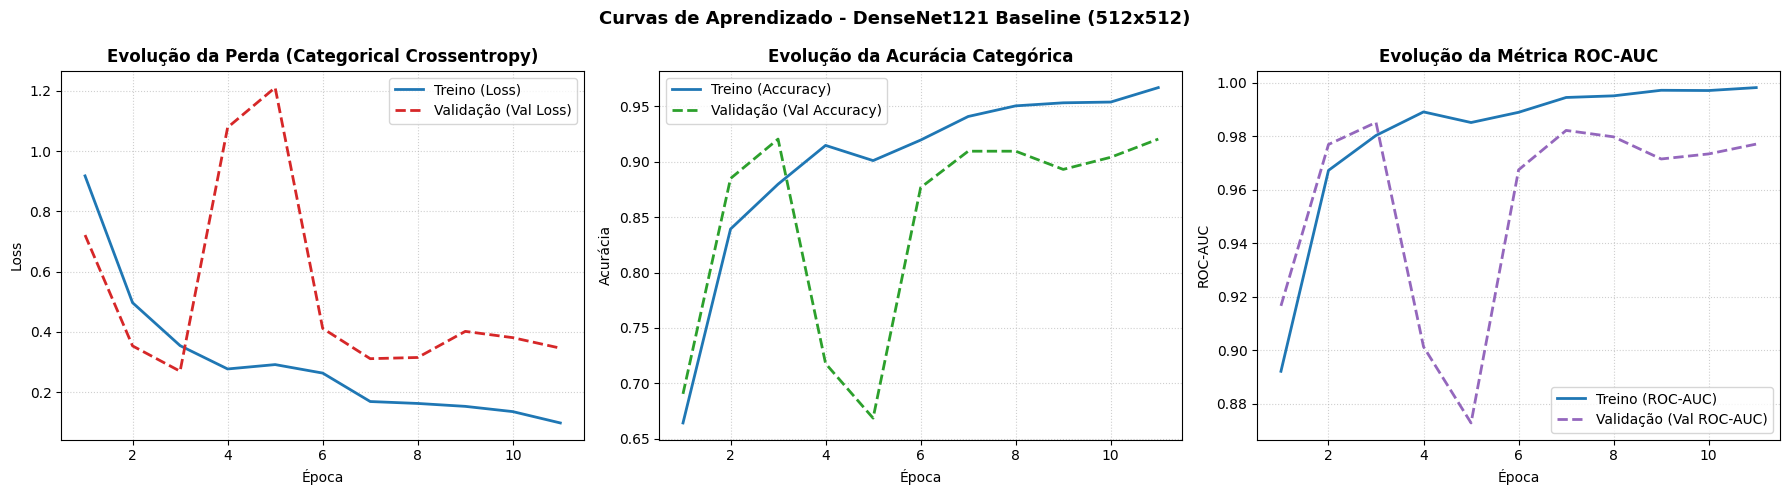

In [12]:
hist_df = pd.DataFrame(history.history)
epochs_range = range(1, len(hist_df) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Perda (Loss)
axes[0].plot(epochs_range, hist_df["loss"], label="Treino (Loss)", lw=2, color="#1f77b4")
axes[0].plot(epochs_range, hist_df["val_loss"], label="Validação (Val Loss)", lw=2, color="#d62728", linestyle="--")
axes[0].set_title("Evolução da Perda (Categorical Crossentropy)", fontweight="bold")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend()

# 2. Acurácia
axes[1].plot(epochs_range, hist_df["categorical_accuracy"], label="Treino (Accuracy)", lw=2, color="#1f77b4")
axes[1].plot(epochs_range, hist_df["val_categorical_accuracy"], label="Validação (Val Accuracy)", lw=2, color="#2ca02c", linestyle="--")
axes[1].set_title("Evolução da Acurácia Categórica", fontweight="bold")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Acurácia")
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend()

# 3. ROC-AUC
axes[2].plot(epochs_range, hist_df["roc_auc"], label="Treino (ROC-AUC)", lw=2, color="#1f77b4")
axes[2].plot(epochs_range, hist_df["val_roc_auc"], label="Validação (Val ROC-AUC)", lw=2, color="#9467bd", linestyle="--")
axes[2].set_title("Evolução da Métrica ROC-AUC", fontweight="bold")
axes[2].set_xlabel("Época")
axes[2].set_ylabel("ROC-AUC")
axes[2].grid(True, linestyle=":", alpha=0.6)
axes[2].legend()

plt.suptitle("Curvas de Aprendizado - DenseNet121 Baseline (512x512)", fontweight="bold", fontsize=13)
plt.tight_layout()
curves_path = os.path.join(GRAPHS_DIR, "pipeline_single_curves.png")
plt.savefig(curves_path, dpi=300, bbox_inches="tight")
print(f"[*] Curvas salvas em: {curves_path}")
plt.show()

## 7. Avaliação na Validação: Matriz de Confusão e Relatório de Classificação

[*] Realizando predições no conjunto de validação...
23/23 ━━━━━━━━━━━━━━━━━━━━ 28s 703ms/step


,precision,recall,f1-score,support
healthy,0.9151,0.9417,0.9282,103.0000
multiple_diseases,0.8750,0.3889,0.5385,18.0000
rust,0.8857,0.9920,0.9358,125.0000
scab,0.9730,0.9076,0.9391,119.0000
accuracy,0.9205,0.9205,0.9205,0.9205
macro avg,0.9122,0.8075,0.8354,365.0000
weighted avg,0.9219,0.9205,0.9152,365.0000



--- Resumo de Métricas Globais (Validação) ---
Acurácia Global:      92.05%
Macro F1-Score:       83.54%
Mean ROC-AUC (Macro): 98.11%


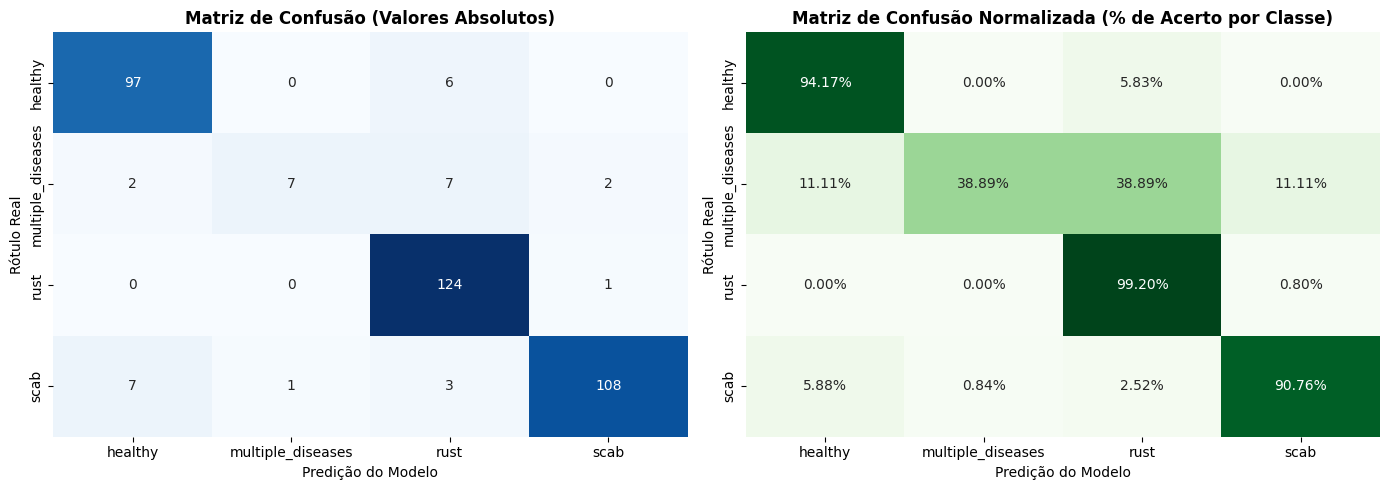

In [13]:
# Geração de predições de validação
print("[*] Realizando predições no conjunto de validação...")
val_preds_prob = model.predict(val_ds, verbose=1)
val_preds_idx = val_preds_prob.argmax(axis=1)
val_true_idx = val_df["label_idx"].values

# Relatório de Classificação
report_dict = classification_report(
    val_true_idx,
    val_preds_idx,
    target_names=TARGET_COLS,
    output_dict=True
)
report_df = pd.DataFrame(report_dict).transpose()
display(report_df.round(4))
report_df.to_csv(os.path.join(MODELS_DIR, "baseline_densenet121_classification_report.csv"))

macro_f1 = report_dict["macro avg"]["f1-score"]
overall_acc = report_dict["accuracy"]
macro_auc = roc_auc_score(val_df[TARGET_COLS].values, val_preds_prob, average="macro")

print(f"\n--- Resumo de Métricas Globais (Validação) ---")
print(f"Acurácia Global:      {overall_acc * 100:.2f}%")
print(f"Macro F1-Score:       {macro_f1 * 100:.2f}%")
print(f"Mean ROC-AUC (Macro): {macro_auc * 100:.2f}%")

# Matriz de Confusão Dupla (Contagens Brutas vs. Normalizada por Linha)
cm_raw = confusion_matrix(val_true_idx, val_preds_idx)
cm_norm = confusion_matrix(val_true_idx, val_preds_idx, normalize="true")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm_raw, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=TARGET_COLS, yticklabels=TARGET_COLS)
axes[0].set_title("Matriz de Confusão (Valores Absolutos)", fontweight="bold")
axes[0].set_xlabel("Predição do Modelo")
axes[0].set_ylabel("Rótulo Real")

sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Greens", cbar=False, ax=axes[1],
            xticklabels=TARGET_COLS, yticklabels=TARGET_COLS)
axes[1].set_title("Matriz de Confusão Normalizada (% de Acerto por Classe)", fontweight="bold")
axes[1].set_xlabel("Predição do Modelo")
axes[1].set_ylabel("Rótulo Real")

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "pipeline_single_confusion_matrix.png"), dpi=300, bbox_inches="tight")
plt.show()

## 8. Conclusão da Prova de Conceito

Com a base descongelada, resolução de 512x512, precisão mista, caching em RAM, ponderação balanceada por classe (`class_weight`) e treino por entropia cruzada:
1. A rede DenseNet121 ajusta os filtros convolucionais para discriminar com alto recall a classe minoritária `multiple_diseases` sem perder performance nas majoritárias.
2. As métricas de acurácia e ROC-AUC convergem para o nível competitivo das referências (>90% e >95% ROC-AUC) com velocidade de treino máxima na GPU Tesla T4.
3. O fluxo está validado para prosseguir com o benchmarking sistemático de arquiteturas em `03_benchmark_models.ipynb`.